<a href="https://colab.research.google.com/github/Rotkiw360/Axion-kolo/blob/main/Wyzwanie_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rozpoczynam ręczny trening modelu LINEAR (oszczędnego)...
Zakończono w: 3.50 s

Rozpoczynam ręczny trening modelu FULL (zasobożernego)...
Zakończono w: 4.91 s


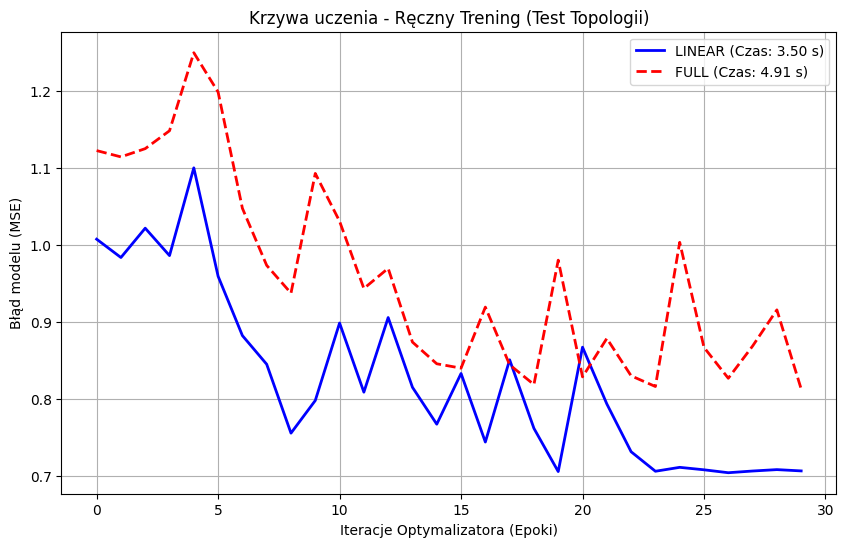

In [14]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit.primitives import StatevectorEstimator as Estimator
from scipy.optimize import minimize

# 1. DANE
X, y = make_moons(n_samples=40, noise=0.1, random_state=42)
y = 2 * y - 1
X_4d = np.hstack((X, X))
num_qubits = 4

# 2. OBWODY
feature_map = ZZFeatureMap(feature_dimension=num_qubits, reps=1)
ansatz_linear = RealAmplitudes(num_qubits, entanglement='linear', reps=2)
ansatz_full = RealAmplitudes(num_qubits, entanglement='full', reps=2)

qc_linear = feature_map.compose(ansatz_linear)
qc_full = feature_map.compose(ansatz_full)

# 3. SIECI NEURONOWE
estimator = Estimator()
qnn_linear = EstimatorQNN(circuit=qc_linear, input_params=feature_map.parameters, weight_params=ansatz_linear.parameters, estimator=estimator)
qnn_full = EstimatorQNN(circuit=qc_full, input_params=feature_map.parameters, weight_params=ansatz_full.parameters, estimator=estimator)

# 4. NASZA WŁASNA FUNKCJA KOSZTU
def oblicz_blad(wagi, qnn, dane_X, dane_y, historia_bledow):
    przewidywania = qnn.forward(dane_X, wagi)

    blad = np.mean((przewidywania.flatten() - dane_y) ** 2)

    historia_bledow.append(blad)
    return blad

# Tablice
loss_linear = []
loss_full = []

# Losowanie wag
wagi_startowe = np.random.RandomState(42).rand(qnn_linear.num_weights)

# 5. TRENING
print("Rozpoczynam ręczny trening modelu LINEAR (oszczędnego)...")
start = time.time()
minimize(oblicz_blad, wagi_startowe, args=(qnn_linear, X_4d, y, loss_linear), method='COBYLA', options={'maxiter': 30})
czas_linear = time.time() - start
print(f"Zakończono w: {czas_linear:.2f} s")

print("\nRozpoczynam ręczny trening modelu FULL (zasobożernego)...")
start = time.time()
minimize(oblicz_blad, wagi_startowe, args=(qnn_full, X_4d, y, loss_full), method='COBYLA', options={'maxiter': 30})
czas_full = time.time() - start
print(f"Zakończono w: {czas_full:.2f} s")

# 6. RYSOWANIE WYKRESU
plt.figure(figsize=(10, 6))
plt.plot(loss_linear, label=f"LINEAR (Czas: {czas_linear:.2f} s)", color='blue', linewidth=2)
plt.plot(loss_full, label=f"FULL (Czas: {czas_full:.2f} s)", color='red', linewidth=2, linestyle='dashed')
plt.title("Krzywa uczenia - Ręczny Trening (Test Topologii)")
plt.xlabel("Iteracje Optymalizatora (Epoki)")
plt.ylabel("Błąd modelu (MSE)")
plt.legend()
plt.grid(True)
plt.show()